# Deliverable 1
Sources used
    - https://frost.met.no/python_example.html and week 5 lecture
    
### Task 1: 


In [18]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import yaml

ModuleNotFoundError: No module named 'yaml'

In [ ]:
client_id = open("../frost_id/client_id.txt").read()

# Dates to get data from
dates = {
    1925: "1925-01-01/1925-12-31",
    2025: "2025-01-01/2025-12-31"
}

# A dictionary to store data by year(dates), and ... 
frost_payloads = {}

endpoint = "https://frost.met.no/observations/v0.jsonld"

# Looping through the dates dict to reduce code replication for task 3
for year, reference_time in dates.items():
    
    # Week 5 lecture have been used for the code inside this loop
    parameters = {
        "sources": "SN17850",
        "elements": "mean(air_temperature P1D)",
        "referencetime": reference_time
    }

    r = requests.get(endpoint, parameters, auth=(client_id, ""))

    assert r.status_code == 200
    frost_payloads[year] = r.json()

AssertionError: 

In [ ]:
# Converts list into dataframe and sets the time as index
# Again doing it with a loop to handle both 2025 and 1925 in same code block
# Week 5 lecture have been used for the code inside the loop 

temperature_data = {}

for year, payload in frost_payloads.items():
    temp_data = [
        {
            "Time": pd.to_datetime(entry["referenceTime"]),
            "T_avg": entry["observations"][0]["value"]
        }
        for entry in payload["data"]
        ]
    
    temperature_data[year] = (pd.DataFrame(temp_data).set_index("Time"))

df_1925 = temperature_data[1925]
df_2025 = temperature_data[2025]

##### Plotting of mean air temperature

In [ ]:
df_2025.plot(
    y="T_avg",
    kind="line",
    linewidth=0.8,
    color="red",
    label="Average Temperature",
    title=("Mean air temperature for 2025 in Ås"),
    xlabel=("Month"),
    ylabel=("Temperature in celsius"),
    )

plt.grid(alpha=0.5)

plt.minorticks_off() # Only showing monthly ticks
plt.show()

NameError: name 'df_2025' is not defined

##### Discussion of plot:
For the first plot we've decided to use a line plot, simply because it is the most informative when looking at time series data of temperature.
A dark blue color have been chosen for high contrast. By using .minorticks_off() we've removed ticks that was difficult to see what was pointing to, only leaving us with ticks for each month. Otherwise, labels and titles have been named to give information about what the plot is about.

From the plot we can see that the highest average temperatures are in july and the coldes month january/february.



Summary table of temperature

In [ ]:
summary_table_2025 = pd.DataFrame({
    "mean": df_2025.mean(),
    "median": df_2025.median(),
    "min": df_2025.min(),
    "max": df_2025.max()
    }).round(1)

# Rename T_avg
summary_table_2025.index = ["Temperature (°C)"]

print(f"Average temperatures in Ås, 2025\n {'_' * 42}")
print(summary_table_2025)

Average temperatures in Ås, 2025
 __________________________________________
                  mean  median   min   max
Temperature (°C)   7.9     8.4 -15.5  23.7


##### Discussion of summary table:
Here we've made a data frame for the summary table, then found statistics by using corresponding statistic methods. We've decided using round to get all the statistics neat and similiar in decimals. 
From the statistics we get the yearly mean of 7.9 celsius and median of 8.4, meaning we might have an asymetrical distribution.

### Task 2

In [ ]:
precipitation_parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "PT6H"
}

# Requesting precipitation data for 2025
precipitation_response = requests.get(
    endpoint, precipitation_parameters, auth=(client_id, "")
)
assert precipitation_response.status_code == 200

# Transforming the data into a Python dictionary
precipitation_payload = precipitation_response.json()
precipitation_payload["data"][0]

# Collecting date and precipitation values from each data entry
precipitation_data = [
    {
        "Time": pd.to_datetime(entry["referenceTime"]),
        "Precipitation": entry["observations"][0]["value"]
    }
    for entry in precipitation_payload["data"]
]

# Creating a DataFrame with date as index
df_precipitation = (
    pd.DataFrame(precipitation_data)
    .set_index("Time")
    .sort_index()
)

df_precipitation.head()

,Precipitation
Time,
2025-01-01 00:00:00+00:00,6.6
2025-01-02 00:00:00+00:00,1.9
2025-01-03 00:00:00+00:00,0.1
2025-01-04 00:00:00+00:00,0.0
2025-01-05 00:00:00+00:00,0.0


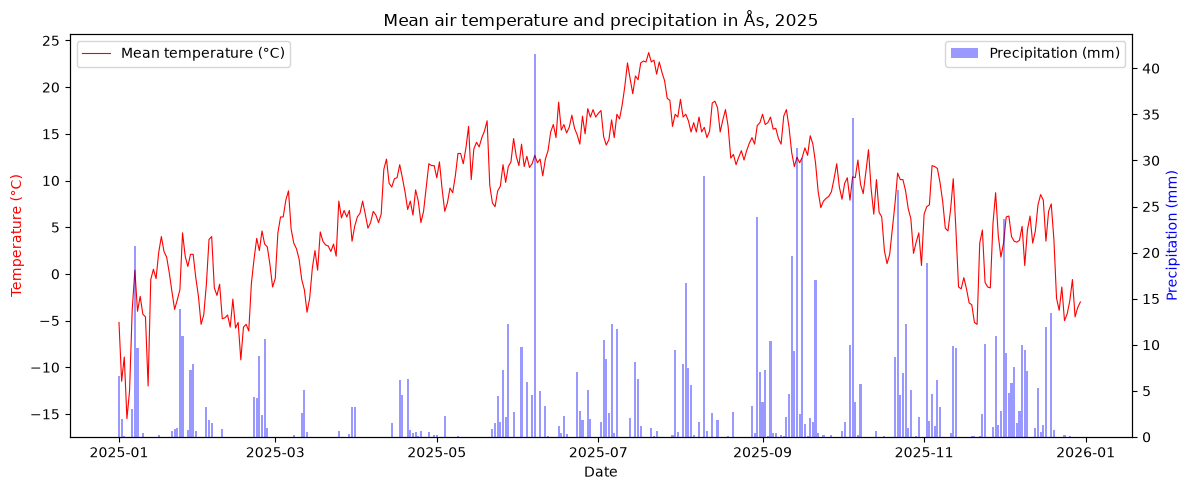

In [25]:
fig, ax_temp = plt.subplots(figsize=(12, 5))

# Temperature plot

ax_temp.plot(
    df_2025.index,
    df_2025["T_avg"],
    color="red",
    linewidth=0.8,
    label="Mean temperature (°C)"
)
ax_temp.set_ylabel("Temperature (°C)", color="red")
ax_temp.set_xlabel("Date")

# Precipitation as bar plot
ax_rain = ax_temp.twinx()
ax_rain.bar(
    df_precipitation.index,
    df_precipitation["Precipitation"],
    color="blue",
    alpha=0.4,
    label="Precipitation (mm)"
)
ax_rain.set_ylabel("Precipitation (mm)", color="blue")

ax_temp.set_title("Mean air temperature and precipitation in Ås, 2025")
ax_temp.legend(loc="upper left")
ax_rain.legend(loc="upper right")

fig.tight_layout()

### Task 3

##### Plot of mean temperatures in 1925 and 2025
The 1925 temperatures have been retrieved earlier in the code (inside the loops in task 1).
This was done to reduce code duplication, therefore only plot and summary table will be shown in this section. 

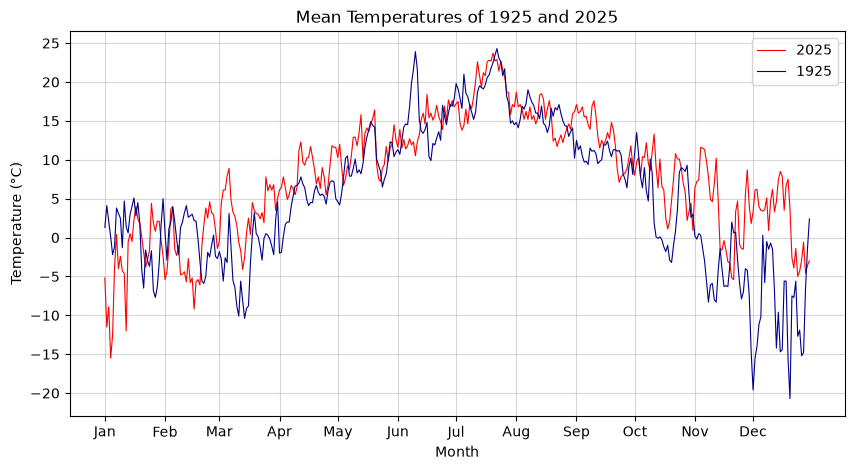

In [ ]:
# Stretching the plot a bit so it is easier to read and assigns an axis to work with
fig, comb_ax = plt.subplots(figsize=(10, 5))

# 2025 data
comb_ax.plot(df_2025.index.dayofyear, df_2025, color="red", linewidth="0.8", label="2025")
# 1925 data
comb_ax.plot(df_1925.index.dayofyear, df_1925, color="darkblue", linewidth="0.8", label="1925")

# Create our own ticks with own labels to get months at x-axis
# These lists was created by AI after summary was made, hence no mention in the txt-file.
comb_ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
comb_ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

# Create more ticks for the y-axis
comb_ax.set_yticks([-20, -15, -10, -5, 0, 5, 10, 15, 20, 25])

plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.title("Mean Temperatures of 1925 and 2025")

plt.legend()
plt.grid(alpha=0.5)
plt.show()

Since the dates in 1925 and 2025 won't nessecarily match up, we use .dayofyear to correct for this (otherwise we would have a plot showing mushed lines to the far left and right). We use .subplots() to guarantee the two dataframes share the same plot, inside we change the width of the plotting canvas. We've chosen two contrasting colors and decreased the line width of both so they dont overlap eachother as much. 

##### Summary Table for 1925 and 2025

In [ ]:
combined = pd.concat(
    [
        df_1925["T_avg"].rename("1925"),
        df_2025["T_avg"].rename("2025")
    ],
    axis=1
)

summary_combined = pd.DataFrame({
    "mean": combined.mean(),
    "median": combined.median(),
    "min": combined.min(),
    "max": combined.max()
    }).round(1)

# naming the column as year
summary_combined.index.name = "Year"

print(f"Average temperatures in Ås 1925 and 2025\n {'_' * 40}")
print(summary_combined)

Average temperatures in Ås 1925 and 2025
 ________________________________________
      mean  median   min   max
Year                          
1925   5.3     5.3 -20.7  24.3
2025   7.9     8.4 -15.5  23.7


##### Discussion of summary
For this summary table we've used .concat to combine the dataframes of 1925 and 2025. Without renaming the T_avg we get some weird outputs, hence the .rename. Otherwise the statistics coding is the same as in task 1, other then the new dataframe. For naming the columns we had to use .index.name instead of just .index for it to work. Again, the printout is the same as task 1. 

##### Some description of the statistics :)
The statistics shows us a bigger range in the 1925 temperatures than 2025. But the important difference will be to look at the mean and median. We can see that the mean and median in 1925 is the same, meaning the temperatures are symmetrical distributed (also colder in 1925 than 2025). Since the mean and median in 2025 don't match up it tells us that the statistics are might be skewed but we can not conclude anything based only on this. The main point, it is hotter on average in 2025 than in 1925. 

### Task 4

In [ ]:
# Task 4: Heatwaves

# Read client credential
try:
    client_id = open("../frost_id/client_id.txt").read().strip()
except FileNotFoundError:
    client_id = open("frost_id/client_id.txt").read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"

def count_heatwaves(
    station_id: str = "SN17850",
    year: int = 2025,
    client_id: str = client_id,
    station_name: str = "Ås",
    output_file: str = "heatwaves.yml",
) -> int:
    """Fetches daily maximum temperatures from the Frost API for a given station and year,

    identifies heatwaves (>= 5 consecutive days with max temperature >= 27.0 °C),
    and saves a summary to a YAML file following the specified structure.
    """
    # Query parameters for daily maximum temperature
    parameters = {
        "sources": station_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year}-12-31",
    }

    # Send request to Frost API
    response = requests.get(endpoint, parameters, auth=(client_id, ""))
    assert (
        response.status_code == 200
    ), f"Error querying Frost API (Status code: {response.status_code})"

    payload = response.json()

    # Extract observation dates and maximum temperature values
    temp_data = []
    for entry in payload.get("data", []):
        ref_date = pd.to_datetime(entry["referenceTime"]).strftime("%Y-%m-%d")
        for obs in entry.get("observations", []):
            if obs.get("elementId") == "max(air_temperature P1D)":
                temp_data.append({"Date": ref_date, "T_max": obs["value"]})
                break

    df = pd.DataFrame(temp_data)

    # Detect heatwaves (>= 5 consecutive days with T_max >= 27.0 °C)
    heatwave_ranges = []
    current_wave = []

    for _, row in df.iterrows():
        if row["T_max"] >= 27.0:
            current_wave.append(row["Date"])
        else:
            if len(current_wave) >= 5:
                start_date = current_wave
                end_date = current_wave[-1]
                heatwave_ranges.append(f"{start_date} - {end_date}")
            current_wave = []

    # Check if a heatwave extended through the final day of the year
    if len(current_wave) >= 5:
        start_date = current_wave
        end_date = current_wave[-1]
        heatwave_ranges.append(f"{start_date} - {end_date}")

    # Build dictionary matching the exact YAML layout
    yaml_summary = {
        "dates": heatwave_ranges,
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }

    # Write summary to .yml file
    with open(output_file, "w", encoding="utf-8") as f:
        yaml.dump(yaml_summary, f, sort_keys=False, allow_unicode=True)

    num_heatwaves = len(heatwave_ranges)
    print(
        f"Analysis complete for {station_name} ({station_id}) in {year}: Found {num_heatwaves} heatwave(s)."
    )
    print(f"Summary successfully saved to '{output_file}'.")

    return num_heatwaves

# Execute function for Ås in 2025
num_waves = count_heatwaves(
    station_id="SN17850", year=2025, station_name="Ås", output_file="heatwaves.yml"
)


NameError: name 'yaml' is not defined

### Task 5

In [ ]:
def moving_average(dataframe: pd.DataFrame, column: str="T_avg", time_window: int=7) -> pd.Series:
    """
    Calculates 7-day moving average for temperature.
        Example: first calculate day 1-7, then 2-8 and so on.
    
    args:
        dataframe: a pandas dataframe of average air temperatures.
        column: name of temperature column, default: T_avg
        time_window: Number of days for moving temp, default: 7

    return:
        rolling_temp: a pandas series of calculated 7-day average
    """
    rolling_temp = dataframe[column].rolling(window=time_window).mean()

    return rolling_temp

moving_average(df_2025).head(10)
#moving_average(df_2025).tail(10)

Time
2025-01-01 00:00:00+00:00         NaN
2025-01-02 00:00:00+00:00         NaN
2025-01-03 00:00:00+00:00         NaN
2025-01-04 00:00:00+00:00         NaN
2025-01-05 00:00:00+00:00         NaN
2025-01-06 00:00:00+00:00         NaN
2025-01-07 00:00:00+00:00   -8.142857
2025-01-08 00:00:00+00:00   -7.971429
2025-01-09 00:00:00+00:00   -6.671429
2025-01-10 00:00:00+00:00   -6.014286
Name: T_avg, dtype: float64

The output of moving_average() gives us NaNs for the first 6 rows, this happens because the function dont have enough days to calculate the average yet. For row 7 we get our first average.

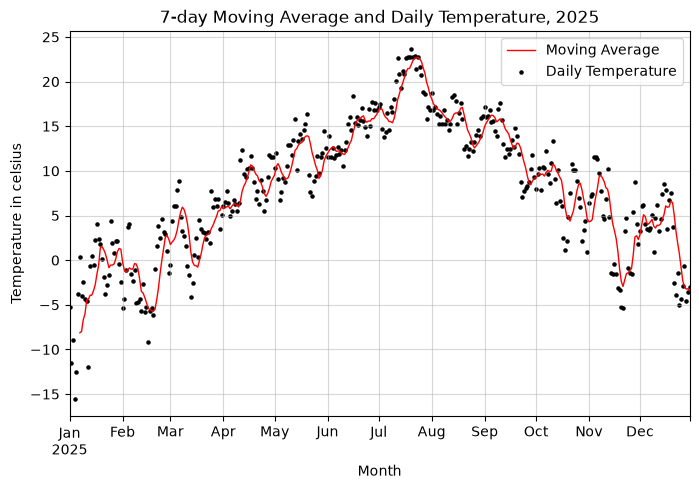

In [ ]:
plt.figure(figsize=(8, 5)) # Changes the size of the plot picture, broading it

av_ax = moving_average(df_2025).plot(
    y="T_avg",
    kind="line",
    linewidth=1,
    color="red",
    label="Moving Average",
    title="7-day Moving Average and Daily Temperature, 2025",
    xlabel="Month",
    ylabel="Temperature in celsius",
    )

av_ax.scatter(df_2025.index, df_2025["T_avg"],
    color="black", s=5, label="Daily Temperature")

plt.grid(alpha=0.5)
plt.legend()
plt.minorticks_off()
plt.show()

For this plot we've used .plot and .scatter to get a line for the moving average and points for the daily temperatures. The plot is built around the moving average function, firstly the line is created and with it title and x/y axis labels. We then add a scatter plot on top of the first plot by using the variable assigned to the moving average.